<a href="https://colab.research.google.com/github/MOISS82/everpeak-analysis/blob/main/S7_Version_Estudiante_Project_ConnectaTel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [ ]:
# importar librerías
import pandas as pd

In [ ]:
#cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [ ]:
# mostrar las primeras 5 filas de plans
print(plans.head())

  plan_name  messages_included  gb_per_month  minutes_included  \
0    Basico                100             5               100   
1   Premium                500            20               600   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute  
0               12         1.2             0.08            0.10  
1               25         1.0             0.05            0.07  


In [ ]:
#mostrar las primeras 5 filas de users
print(users.head())

   user_id  age churn_date         city first_name  last_name    reg_date  \
0     1000   52        NaN    Краснодар     Рафаил  Верещагин  2018-05-25   
1     1001   41        NaN       Москва       Иван       Ежов  2018-11-01   
2     1002   59        NaN  Стерлитамак    Евгений  Абрамович  2018-06-17   
3     1003   23        NaN       Москва      Белла   Белякова  2018-08-17   
4     1004   68        NaN  Новокузнецк    Татьяна   Авдеенко  2018-05-14   

  tariff  
0  ultra  
1  smart  
2  smart  
3  ultra  
4  ultra  


In [ ]:
#mostrar Las primeras 5 filas de usage
print(usage.head())

   id  user_id  type                           date  duration  length
0   1    10332  call  2024-01-01 00:00:00.000000000      0.09     NaN
1   2    11458  text  2024-01-01 00:06:30.969774244       NaN    39.0
2   3    11777  text  2024-01-01 00:13:01.939548488       NaN    36.0
3   4    10682  call  2024-01-01 00:19:32.909322733      1.53     NaN
4   5    12742  call  2024-01-01 00:26:03.879096977      4.84     NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [ ]:


# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (500, 8)
usage (40000, 6)


In [ ]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [ ]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     500 non-null    int64 
 1   age         500 non-null    int64 
 2   churn_date  38 non-null     object
 3   city        500 non-null    object
 4   first_name  500 non-null    object
 5   last_name   500 non-null    object
 6   reg_date    500 non-null    object
 7   tariff      500 non-null    object
dtypes: int64(2), object(6)
memory usage: 31.4+ KB


In [ ]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---


## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.


In [ ]:
# cantidad de nulos para users
print("Cantidad de valores nulos")
print(users.isna().sum())

print("Proporción de valores nulos")
print(users.isna().mean())

Cantidad de valores nulos
user_id         0
age             0
churn_date    462
city            0
first_name      0
last_name       0
reg_date        0
tariff          0
dtype: int64
Proporción de valores nulos
user_id       0.000
age           0.000
churn_date    0.924
city          0.000
first_name    0.000
last_name     0.000
reg_date      0.000
tariff        0.000
dtype: float64


In [ ]:
# cantidad de nulos para usage
print("Cantidad de valores nulos")
print(usage.isna().sum())

print("Proporción de valores nulos")
print(usage.isna().mean())

Cantidad de valores nulos
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
Proporción de valores nulos
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [ ]:
# explorar columnas numéricas de users
print(users.describe())

           user_id        age
count   500.000000  500.00000
mean   1249.500000   46.58800
std     144.481833   16.66763
min    1000.000000   18.00000
25%    1124.750000   32.00000
50%    1249.500000   46.00000
75%    1374.250000   62.00000
max    1499.000000   75.00000


- La columna `user_id:No presenta anoma
lias evidentes
- La columna `age`: No se observam edades negativas ni valores fuera del rango esperado


In [ ]:
# explorar columnas numéricas de usage
print(usage.describe())

                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000


- Las columnas `id` y `user_id`son identificadores, que tengan repetidos es normal..
- Las columnas duration y length: presnetan valores minimos de 0. Es necesario investigar los valores extremos y los registros con cero.

In [ ]:
# explorar columnas categóricas de users
columnas_user = ['city', 'tariff']
for columna in columnas_user:
  print("Columna:",columna)
  print(users[columna].unique())
  print()

Columna: city
['Краснодар' 'Москва' 'Стерлитамак' 'Новокузнецк' 'Набережные Челны'
 'Ульяновск' 'Челябинск' 'Пермь' 'Тюмень' 'Самара' 'Санкт-Петербург'
 'Иваново' 'Чебоксары' 'Омск' 'Уфа' 'Томск' 'Чита' 'Мурманск'
 'Петрозаводск' 'Тверь' 'Екатеринбург' 'Махачкала' 'Вологда' 'Череповец'
 'Ярославль' 'Сочи' 'Хабаровск' 'Ставрополь' 'Рязань' 'Улан-Удэ' 'Тула'
 'Саратов' 'Ростов-на-Дону' 'Казань' 'Иркутск' 'Курск' 'Калуга' 'Якутск'
 'Астрахань' 'Химки' 'Владикавказ' 'Волгоград' 'Саранск' 'Ижевск'
 'Новосибирск' 'Брянск' 'Тольятти' 'Нижний Тагил' 'Орёл' 'Белгород'
 'Воронеж' 'Волжский' 'Курган' 'Барнаул' 'Красноярск' 'Архангельск'
 'Липецк' 'Кемерово' 'Киров' 'Сургут' 'Пенза' 'Магнитогорск'
 'Нижний Новгород' 'Кострома' 'Владивосток' 'Тамбов' 'Балашиха'
 'Севастополь' 'Калининград' 'Оренбург' 'Смоленск' 'Нижневартовск'
 'Владимир' 'Новороссийск' 'Грозный' 'Подольск']

Columna: tariff
['ultra' 'smart']



- La columna `city` tiene diferentes ciudades de Rusia
- La columna `plan tiene dos categorias: ultra y smart

In [ ]:
# explorar columna categórica de usage
print(usage['type'].unique())

['call' 'text']


- La columna `type` contiene categorias call y text


---
✍️ **Comentario**: En la exploración numérica del dataset usage se identificaron valores mínimos de cero en las columnas duration y length, así como valores máximos de 120 y 1,490, respectivamente. Estos registros requieren una revisión para determinar si representan datos reales o valores utilizados como indicadores de ausencia de información.

En users, las columnas age y user_id no presentan anomalías evidentes en sus rangos. Las columnas categóricas city, tariff y type tampoco muestran categorías inesperadas. Se identificaron dos tarifas (ultra y smart) y dos tipos de actividad (call y text).

Se deberia Revisar los registros con valores de cero y los valores extremos de duration y length para validar su significado. No eliminarlos automáticamente, ya que podrían representar situaciones reales de uso.

Conservar los identificadores y las categorías válidas. Si se confirman valores utilizados como sentinels, convertirlos en valores nulos y evaluar su tratamiento mediante imputación o eliminación, según su impacto en el análisis.




### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [ ]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'],errors='coerce')

In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date']= pd.to_datetime(usage['date'], errors='coerce')

In [ ]:
# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].dt.year.value_counts().sort_index())

2018    500
Name: reg_date, dtype: int64


En `reg_date`, almacena fecha en que cada usuario se registro o compro el servicio.

In [ ]:
# Revisar los años presentes en `date` de usage
print(usage['date'].dt.year.value_counts().sort_index())


2024.0    39950
Name: date, dtype: int64


En `date`, aparede el año registrado y la cantidad de registros de ese año.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

En la columna date del dataset usage se identificaron 39,950 registros correspondientes al año 2024. No se observaron años posteriores al límite establecido por el ejercicio. Sin embargo, es necesario revisar las fechas nulas o inválidas y verificar las columnas reg_date y churn_date del dataset users, ya que anteriormente no se obtuvieron resultados al agrupar sus años.

Conservaría las fechas válidas de 2024. Las fechas futuras o fuera del rango permitido deberán investigarse y corregirse si existe evidencia del error. Si no es posible recuperar la fecha original, las marcaría como valores nulos (NaT) y evaluaría su impacto antes de eliminar registros.



**Fechas fuera de rango**  
En la columna date de usage se encontraron 39,950 registros correspondientes al año 2024. No se identificaron años posteriores al límite establecido. Sin embargo, es necesario verificar las fechas nulas y las columnas de fecha de users.

Conservaría las fechas válidas. Si encuentro fechas futuras o imposibles, investigaría su origen y corregiría los errores cuando sea posible.


---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age']!=-999, 'age'].median()
users['age'] = users['age'].replace(999, age_mediana)

# Verificar cambios
users['age'].describe()

count    500.00000
mean      46.58800
std       16.66763
min       18.00000
25%       32.00000
50%       46.00000
75%       62.00000
max       75.00000
Name: age, dtype: float64

In [ ]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?',pd.NA)

# Verificar cambios
users['city'].value_counts(dropna=False)

Москва             99
Санкт-Петербург    39
Новосибирск        16
Омск               14
Казань             14
                   ..
Нижневартовск       1
Архангельск         1
Иваново             1
Подольск            1
Химки               1
Name: city, Length: 76, dtype: int64

In [ ]:
# Marcar fechas futuras como NA para reg_date

users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

users.loc[users['reg_date'] > pd.Timestamp.today(), 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].describe()

count                     500
unique                    270
top       2018-05-28 00:00:00
freq                        8
first     2018-01-01 00:00:00
last      2018-12-31 00:00:00
Name: reg_date, dtype: object

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration
usage.groupby('type')['duration'].apply(lambda x: x.isna().mean() * 100)


type
call     0.000000
text    99.927576
Name: duration, dtype: float64

In [ ]:
# Verificación MAR en usage (Missing At Random) para length
usage.groupby('type')['length'].apply(
    lambda x: x.isna().mean() * 100)


type
call    99.932991
text     0.000000
Name: length, dtype: float64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

Los valores nulos en las columnas duration y length están relacionados con la variable type, debido a que cada tipo de registro puede representar un evento con características diferentes. Por lo tanto, se considera que existe evidencia de un mecanismo MAR. Se decide conservar los valores nulos, ya que representan información que no aplica necesariamente a todos los tipos de registros y sustituirlos podría generar datos incorrectos.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [ ]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({
    'is_text': 'sum',
    'is_call': 'sum',
    'duration': 'sum'
}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={'is_text':'cant_mensajes',
                                    'is_call':'çant_llamadas',
                                    'duration':'cant_minutos_llamada'})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,çant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg,on='user_id', how='left')
user_profile.head(5)

,user_id,age,churn_date,city,first_name,last_name,reg_date,tariff,cant_mensajes,çant_llamadas,cant_minutos_llamada
0,1000,52,NaN,Краснодар,Рафаил,Верещагин,2018-05-25,ultra,NaN,NaN,NaN
1,1001,41,NaN,Москва,Иван,Ежов,2018-11-01,smart,NaN,NaN,NaN
2,1002,59,NaN,Стерлитамак,Евгений,Абрамович,2018-06-17,smart,NaN,NaN,NaN
3,1003,23,NaN,Москва,Белла,Белякова,2018-08-17,ultra,NaN,NaN,NaN
4,1004,68,NaN,Новокузнецк,Татьяна,Авдеенко,2018-05-14,ultra,NaN,NaN,NaN


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [ ]:
# Resumen estadístico de las columnas numéricas
user_profile.describe()


,user_id,age,cant_mensajes,çant_llamadas,cant_minutos_llamada
count,500.000000,500.00000,0.0,0.0,0.0
mean,1249.500000,46.58800,NaN,NaN,NaN
std,144.481833,16.66763,NaN,NaN,NaN
min,1000.000000,18.00000,NaN,NaN,NaN
25%,1124.750000,32.00000,NaN,NaN,NaN
50%,1249.500000,46.00000,NaN,NaN,NaN
75%,1374.250000,62.00000,NaN,NaN,NaN
max,1499.000000,75.00000,NaN,NaN,NaN


In [ ]:
# Preparar tabla de llamadas
calls_usage = calls[['id', 'user_id', 'call_date', 'duration']].copy()

calls_usage = calls_usage.rename(
    columns={'call_date': 'date'}
)

calls_usage['type'] = 'call'

# Preparar tabla de mensajes
messages_usage = messages[['id', 'user_id', 'message_date']].copy()

messages_usage = messages_usage.rename(
    columns={'message_date': 'date'}
)

messages_usage['type'] = 'text'
messages_usage['duration'] = np.nan

# Unificar llamadas y mensajes
usage = pd.concat(
    [calls_usage, messages_usage],
    ignore_index=True
)

# Verificar resultado
usage.head(10)

,id,user_id,date,duration,type
0,1000_0,1000,2018-07-25,0.00,call
1,1000_1,1000,2018-08-17,0.00,call
2,1000_2,1000,2018-06-11,2.85,call
3,1000_3,1000,2018-09-21,13.80,call
4,1000_4,1000,2018-12-15,5.18,call
5,1000_5,1000,2018-11-02,0.00,call
6,1000_6,1000,2018-10-18,0.00,call
7,1000_7,1000,2018-08-22,18.31,call
8,1000_8,1000,2018-09-15,18.44,call
9,1000_9,1000,2018-08-15,0.00,call


In [ ]:
import numpy as np

In [ ]:
# Preparar tabla de mensajes
messages_usage = messages[['id', 'user_id', 'message_date']].copy()

messages_usage = messages_usage.rename(
    columns={'message_date': 'date'}
)

messages_usage['type'] = 'text'
messages_usage['duration'] = np.nan

In [ ]:
# Unificar llamadas y mensajes
usage = pd.concat(
    [calls_usage, messages_usage],
    ignore_index=True
)

# Verificar resultado
usage.head(10)

,id,user_id,date,duration,type
0,1000_0,1000,2018-07-25,0.00,call
1,1000_1,1000,2018-08-17,0.00,call
2,1000_2,1000,2018-06-11,2.85,call
3,1000_3,1000,2018-09-21,13.80,call
4,1000_4,1000,2018-12-15,5.18,call
5,1000_5,1000,2018-11-02,0.00,call
6,1000_6,1000,2018-10-18,0.00,call
7,1000_7,1000,2018-08-22,18.31,call
8,1000_8,1000,2018-09-15,18.44,call
9,1000_9,1000,2018-08-15,0.00,call


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

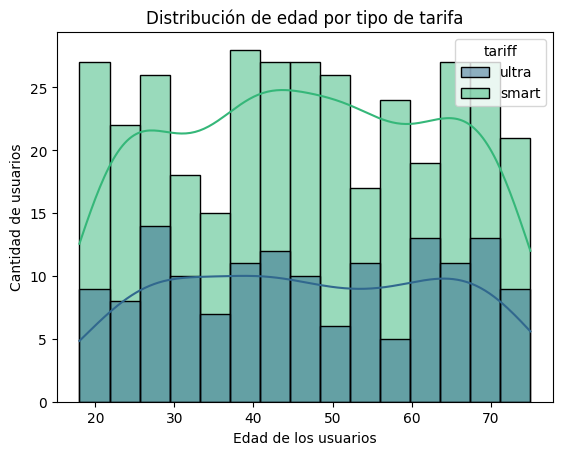

In [ ]:
# Histograma para visualizar la edad (age)
sns.histplot(
    data=user_profile,
    x='age',
    hue='tariff',
    bins=15,
    kde=True,
    palette='viridis'
)

plt.title('Distribución de edad por tipo de tarifa')
plt.xlabel('Edad de los usuarios')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights:
- La distribución de edades es amplia y relativamente equilibrada, sin presentar un sesgo pronunciado hacia alguno de los extremos.
- Los usuarios del plan Smart representan una mayor cantidad de registros que los del plan Ultra.
- Ambos planes presentan usuarios de diferentes rangos de edad, por lo que no se observa una concentración exclusiva de algún grupo etario en una tarifa determinada.

In [ ]:
# Contar mensajes por usuario
messages_agg = messages.groupby('user_id').agg(
    cant_mensajes=('id', 'count')
).reset_index()

In [ ]:
# Contar llamadas y sumar minutos por usuario
calls_agg = calls.groupby('user_id').agg(
    cant_llamadas=('id', 'count'),
    cant_minutos_llamada=('duration', 'sum')
).reset_index()

In [ ]:
# Combinar usuarios con mensajes
user_profile = users.merge(
    messages_agg,
    on='user_id',
    how='left'
)

# Incorporar información de llamadas
user_profile = user_profile.merge(
    calls_agg,
    on='user_id',
    how='left'
)

# Reemplazar valores nulos por cero
columnas = [
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

user_profile[columnas] = user_profile[columnas].fillna(0)

In [ ]:
print(user_profile.columns.tolist())

['user_id', 'age', 'churn_date', 'city', 'first_name', 'last_name', 'reg_date', 'tariff', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']


In [ ]:
user_profile[
    ['user_id', 'tariff', 'cant_mensajes',
     'cant_llamadas', 'cant_minutos_llamada']
].head(10)


,user_id,tariff,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,1000,ultra,496.0,368.0,2418.24
1,1001,smart,0.0,122.0,799.46
2,1002,smart,70.0,217.0,1431.17
3,1003,ultra,380.0,520.0,3600.52
4,1004,ultra,1192.0,176.0,921.21
5,1005,smart,552.0,888.0,6242.65
6,1006,smart,0.0,506.0,3289.36
7,1007,smart,225.0,612.0,4139.47
8,1008,smart,56.0,52.0,320.84
9,1009,smart,110.0,290.0,2056.31


In [ ]:
user_profile[
    ['cant_mensajes',
     'cant_llamadas',
     'cant_minutos_llamada']
].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,500.000000,500.000000,500.000000
mean,246.072000,405.214000,2737.580080
std,267.456765,294.039682,1988.626076
min,0.000000,0.000000,0.000000
25%,42.000000,176.000000,1162.647500
50%,164.500000,338.000000,2305.490000
75%,370.000000,585.000000,3972.967500
max,1463.000000,1760.000000,12258.200000


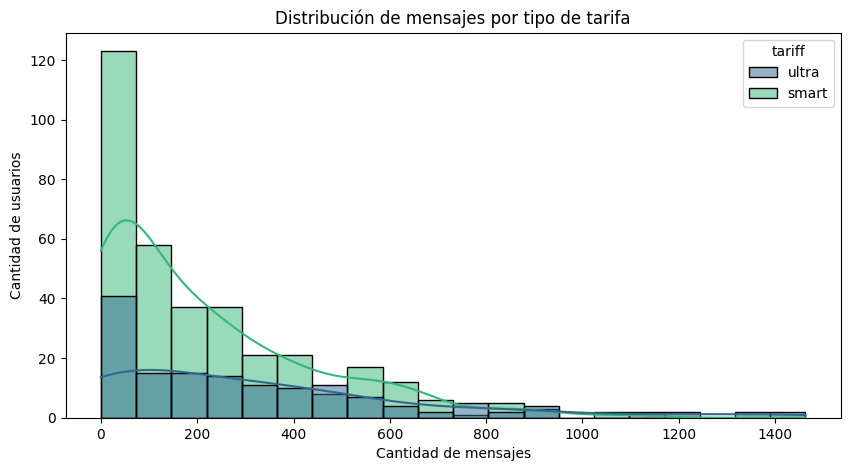

In [ ]:
# Histograma para visualizar la cant_mensajes
plt.figure(figsize=(10, 5))

sns.histplot(
    data=user_profile,
    x='cant_mensajes',
    hue='tariff',
    bins=20,
    kde=True,
    palette='viridis'
)

plt.title('Distribución de mensajes por tipo de tarifa')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')

plt.show()


Insights:

La distribución de mensajes presenta una asimetría positiva (sesgo hacia la derecha), lo que indica que la mayoría de los usuarios tiene un consumo moderado, mientras que un grupo reducido envía cantidades considerablemente mayores.

El plan Smart concentra una mayor cantidad de usuarios en los rangos bajos de consumo.

Ambos planes presentan una cola hacia valores elevados, con usuarios que superan los 1,000 mensajes.

Se identifican posibles valores extremos que deberán analizarse antes de determinar si requieren algún tratamiento.

Text(0, 0.5, 'Cantidad de usuarios')

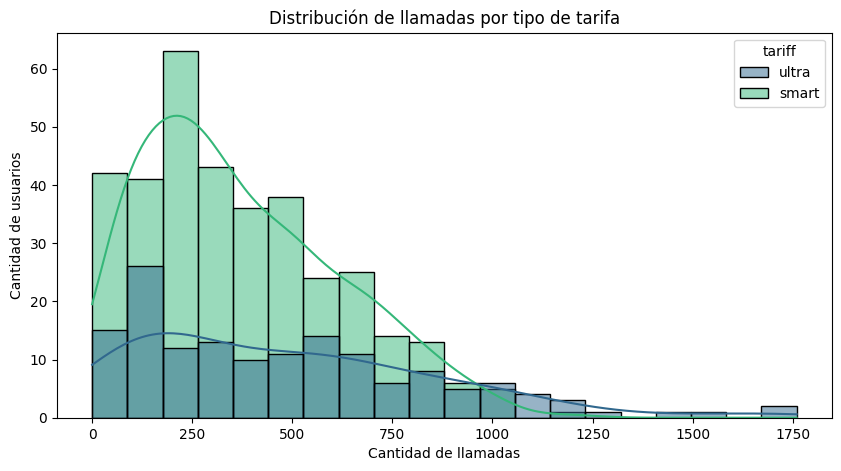

In [ ]:
# Histograma para visualizar la cant_llamadas
plt.figure(figsize=(10, 5))

sns.histplot(
    data=user_profile,
    x='cant_llamadas',
    hue='tariff',
    bins=20,
    kde=True,
    palette='viridis'
)

plt.title('Distribución de llamadas por tipo de tarifa')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')

💡Insights:

La distribución de llamadas presenta una asimetría positiva (sesgo hacia la derecha), indicando que la mayoría de los usuarios realiza una cantidad moderada de llamadas y un grupo reducido registra una actividad considerablemente mayor.

El plan Smart concentra una mayor cantidad de usuarios, principalmente entre 150 y 400 llamadas.

El plan Ultra presenta menor frecuencia de usuarios, aunque también registra consumos elevados.

Se identifican posibles valores extremos por encima de las 1,000 llamadas, que deberán analizarse para determinar su relevancia.

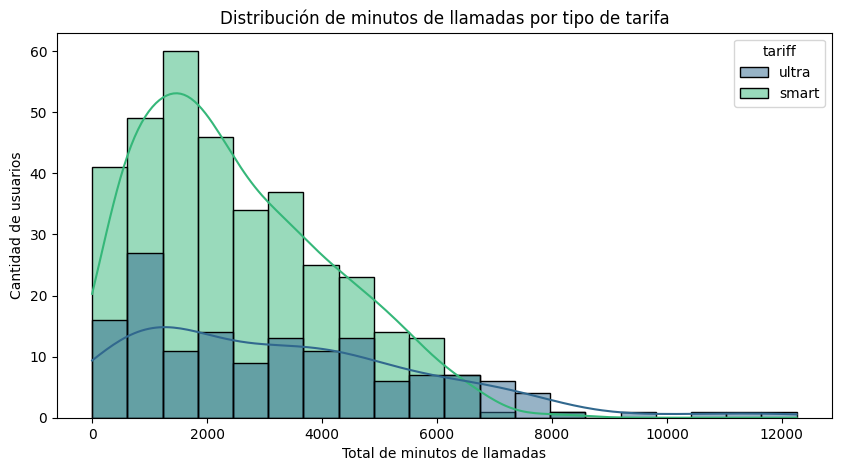

In [ ]:
# Histograma para visualizar la cant_minutos_llamada
plt.figure(figsize=(10, 5))

sns.histplot(
    data=user_profile,
    x='cant_minutos_llamada',
    hue='tariff',
    bins=20,
    kde=True,
    palette='viridis'
)

plt.title('Distribución de minutos de llamadas por tipo de tarifa')
plt.xlabel('Total de minutos de llamadas')
plt.ylabel('Cantidad de usuarios')

plt.show()



💡Insights:

La distribución de minutos de llamadas presenta una asimetría positiva (sesgo hacia la derecha), lo que indica que la mayoría de los usuarios concentra su consumo en niveles bajos y medios, mientras que un grupo reducido acumula una cantidad considerablemente mayor de minutos.

El plan Smart concentra una mayor cantidad de usuarios, principalmente entre 1,000 y 3,000 minutos.

El plan Ultra presenta una menor frecuencia de usuarios, pero alcanza consumos elevados que superan los 10,000 minutos.

Se identifican posibles valores extremos que deberán analizarse antes de determinar si requieren algún tratam

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

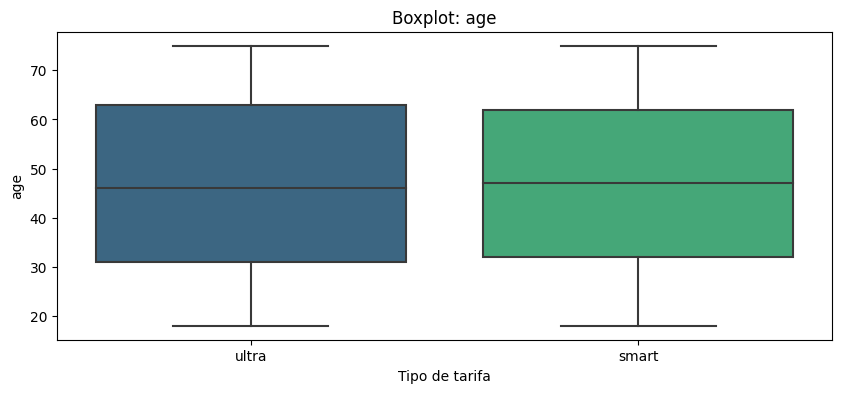

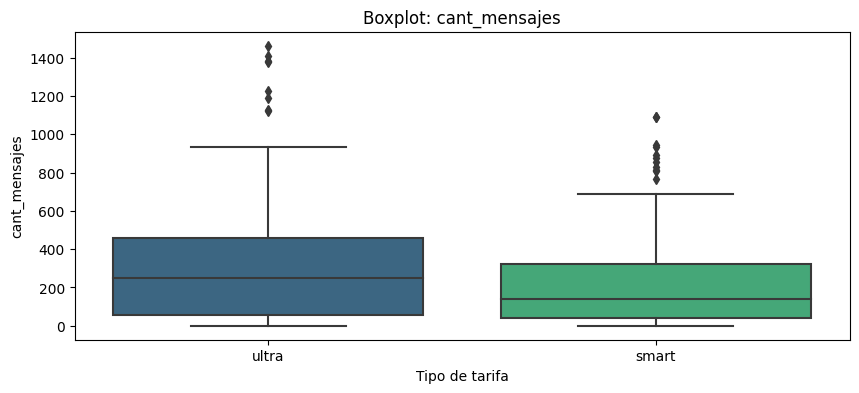

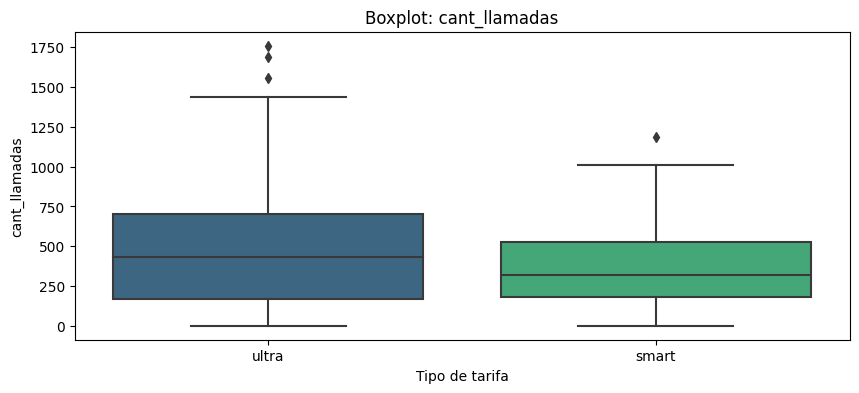

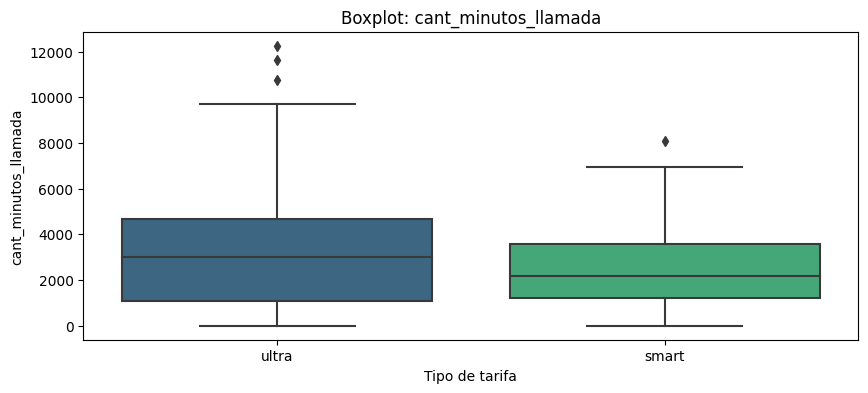

In [ ]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:

    plt.figure(figsize=(10, 4))

    sns.boxplot(
        data=user_profile,
        x='tariff',
        y=col,
        palette='viridis'
    )

    plt.title(f'Boxplot: {col}')
    plt.xlabel('Tipo de tarifa')
    plt.ylabel(col)

    plt.show()

💡Insights:

Age: No presenta outliers visibles en ninguna de las dos tarifas. Los valores de edad se encuentran dentro de los rangos esperados.

cant_mensajes: Presenta outliers en ambas tarifas, principalmente en el extremo superior. Algunos usuarios registran cantidades de mensajes considerablemente mayores al comportamiento habitual.

cant_llamadas: Presenta outliers en Smart y Ultra, con usuarios que realizan una cantidad elevada de llamadas, especialmente en la tarifa Ultra.

cant_minutos_llamada: Presenta outliers en ambas tarifas. Ultra muestra los valores extremos más elevados, superando los 10,000 minutos.

Conclusión: Los valores atípicos se concentran principalmente en las variables de consumo. Se recomienda conservarlos inicialmente, ya que pueden representar comportamientos reales de usuarios intensivos y no necesariamente errores en los registros.

In [ ]:
# Calcular límites con el método IQR
columnas_limites = [
    'age',
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

for col in columnas_limites:

    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    print(f'\nVariable: {col}')
    print(f'Límite inferior: {limite_inferior:.2f}')
    print(f'Límite superior: {limite_superior:.2f}')




Variable: age
Límite inferior: -13.00
Límite superior: 107.00

Variable: cant_mensajes
Límite inferior: -450.00
Límite superior: 862.00

Variable: cant_llamadas
Límite inferior: -437.50
Límite superior: 1198.50

Variable: cant_minutos_llamada
Límite inferior: -3052.83
Límite superior: 8188.45


In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()




,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,500.00000,500.000000,500.000000,500.000000
mean,46.58800,246.072000,405.214000,2737.580080
std,16.66763,267.456765,294.039682,1988.626076
min,18.00000,0.000000,0.000000,0.000000
25%,32.00000,42.000000,176.000000,1162.647500
50%,46.00000,164.500000,338.000000,2305.490000
75%,62.00000,370.000000,585.000000,3972.967500
max,75.00000,1463.000000,1760.000000,12258.200000


💡Insights:

cant_mensajes: Mantener los outliers. El valor máximo es de 1,463 mensajes, superior al límite IQR de 862. Representa posibles usuarios intensivos y no necesariamente errores.

cant_llamadas: Mantener los outliers. El máximo registrado es de 1,760 llamadas, superior al límite de 1,198.50. Estos valores pueden representar patrones reales de uso.

cant_minutos_llamada: Mantener los outliers. El máximo es de 12,258.20 minutos, superando el límite de 8,188.45. Se considera un consumo elevado que debe conservarse mientras no exista evidencia de error.

Conclusión: Las variables de consumo presentan valores atípicos superiores. Se decide conservarlos porque pueden representar comportamientos reales de los usuarios. Su eliminación podría ocasionar pérdida de información relevante y modificar la interpretación del consumo de los clientes.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:
# Crear columna grupo_uso
def clasificar_uso(row):

    if row['cant_llamadas'] < 5 and row['cant_mensajes'] < 5:
        return 'Bajo uso'

    elif row['cant_llamadas'] < 10 and row['cant_mensajes'] < 10:
        return 'Uso medio'

    else:
        return 'Alto uso'


user_profile['grupo_uso'] = user_profile.apply(
    clasificar_uso,
    axis=1
)

In [ ]:
# verificar cambios
user_profile.head()

,user_id,age,churn_date,city,first_name,last_name,reg_date,tariff,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,1000,52,NaN,Краснодар,Рафаил,Верещагин,2018-05-25,ultra,496.0,368.0,2418.24,Alto uso
1,1001,41,NaN,Москва,Иван,Ежов,2018-11-01,smart,0.0,122.0,799.46,Alto uso
2,1002,59,NaN,Стерлитамак,Евгений,Абрамович,2018-06-17,smart,70.0,217.0,1431.17,Alto uso
3,1003,23,NaN,Москва,Белла,Белякова,2018-08-17,ultra,380.0,520.0,3600.52,Alto uso
4,1004,68,NaN,Новокузнецк,Татьяна,Авдеенко,2018-05-14,ultra,1192.0,176.0,921.21,Alto uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [ ]:
# Crear columna grupo_edad
def clasificar_edad(edad):

    if edad < 30:
        return 'Joven'

    elif edad < 60:
        return 'Adulto'

    else:
        return 'Adulto Mayor'


user_profile['grupo_edad'] = user_profile['age'].apply(
    clasificar_edad
)

In [ ]:
# verificar cambios
user_profile.head()

,user_id,age,churn_date,city,first_name,last_name,reg_date,tariff,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,1000,52,NaN,Краснодар,Рафаил,Верещагин,2018-05-25,ultra,496.0,368.0,2418.24,Alto uso,Adulto
1,1001,41,NaN,Москва,Иван,Ежов,2018-11-01,smart,0.0,122.0,799.46,Alto uso,Adulto
2,1002,59,NaN,Стерлитамак,Евгений,Абрамович,2018-06-17,smart,70.0,217.0,1431.17,Alto uso,Adulto
3,1003,23,NaN,Москва,Белла,Белякова,2018-08-17,ultra,380.0,520.0,3600.52,Alto uso,Joven
4,1004,68,NaN,Новокузнецк,Татьяна,Авдеенко,2018-05-14,ultra,1192.0,176.0,921.21,Alto uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

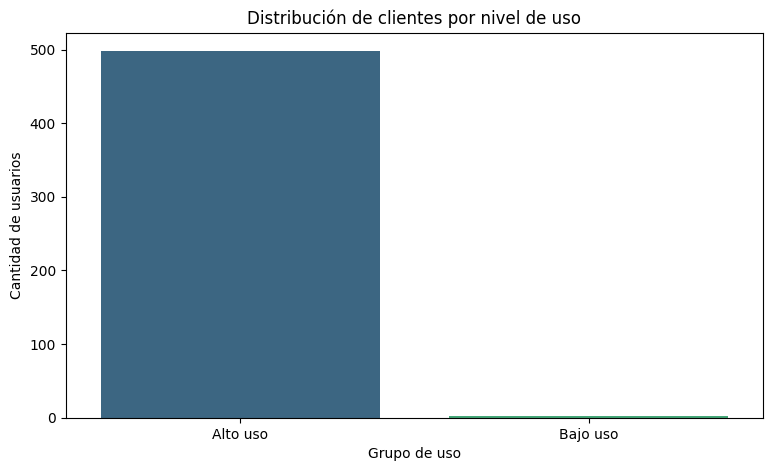

In [ ]:
# Visualización de los segmentos por uso


plt.figure(figsize=(9, 5))

sns.countplot(
    data=user_profile,
    x='grupo_uso',
    palette='viridis'
)

plt.title('Distribución de clientes por nivel de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')

plt.show()

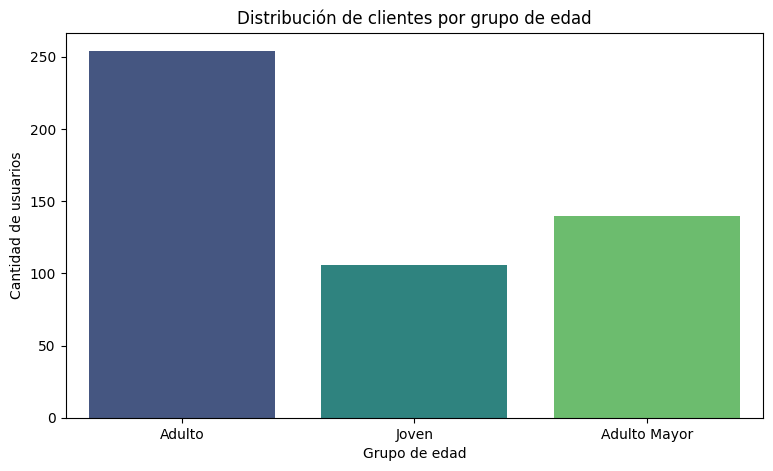

In [ ]:
# Visualización de los segmentos por edad
plt.figure(figsize=(9, 5))

sns.countplot(
    data=user_profile,
    x='grupo_edad',
    palette='viridis'
)

plt.title('Distribución de clientes por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')

plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

Problemas detectados en los datos

Durante la exploración y limpieza de los datos se identificaron los siguientes aspectos:

Se detectaron valores sentinel en la variable age (-999), que fueron sustituidos por la mediana.

En la variable city se identificaron valores desconocidos (?), que se reemplazaron por valores nulos.

Se revisaron las fechas de registro para identificar fechas fuera de rango.

Se encontró una incompatibilidad entre los identificadores de users.csv y usage.csv, por lo que fue necesario reconstruir las métricas de actividad utilizando calls.csv y messages.csv.

La base de usuarios contiene 500 registros. Se encontraron coincidencias con 492 usuarios en llamadas y 426 en mensajes.

Los registros sin actividad coincidente fueron completados con cero en las métricas de consumo. Es necesario validar que correspondan realmente a usuarios sin actividad y no a información faltante.

Resultado: Se obtuvo una base integrada de 500 usuarios con información de edad, ciudad, tarifa, mensajes, llamadas y minutos acumulados.

2. 👥 Segmentos por Edad

Se clasificaron los usuarios en tres grupos:


Joven: menores de 30 años.


Adulto: de 30 a 59 años.

Adulto Mayor: 60 años o más.

Resultados estadísticos:

Edad promedio: 46.59 años.

Mediana: 46 años.

Edad mínima: 18 años.

Edad máxima: 75 años.

No se identificaron valores atípicos mediante el método IQR.

Interpretación: La base presenta usuarios de diferentes grupos de edad, con una edad central cercana a los 46 años. Esto permite considerar estrategias comerciales diferenciadas por etapa de vida y necesidades de comunicación.

3. 📊 Segmentos por Nivel de Uso

Se clasificaron los usuarios de acuerdo con su cantidad de llamadas y mensajes:

Bajo uso: menos de 5 llamadas y menos de 5 mensajes.

Uso medio: menos de 10 llamadas y menos de 10 mensajes, sin cumplir la condición de bajo uso.

Alto uso: el resto de los casos.


Estadísticas de consumo:

Mensajes: promedio de 246.07 y mediana de 164.5.

Llamadas: promedio de 405.21 y mediana de 338.

Minutos de llamadas: promedio de 2,737.58 y mediana de 2,305.49.

Comparación por edad y nivel de uso:

Adultos: 99.2% de alto uso y 0.8% de bajo uso.

Adultos mayores: 100% de alto uso.

Jóvenes: 100% de alto uso.

Interpretación: Existe una concentración muy elevada de usuarios en la categoría de alto uso. Esto indica que los umbrales establecidos para la segmentación son demasiado bajos frente al consumo observado y no permiten diferenciar adecuadamente los patrones de comportamiento.

4. 📈 Análisis de distribuciones y valores atípicos

Se realizaron histogramas para analizar edad, mensajes, llamadas y minutos, comparando las tarifas Smart y Ultra.

Principales hallazgos:

Edad: presenta una distribución amplia, sin diferencias visuales pronunciadas entre las tarifas.

Mensajes: la distribución presenta asimetría positiva. La mayoría de los usuarios registra consumos moderados y algunos presentan cantidades superiores a 1,000 mensajes.

Llamadas: se observa una concentración de usuarios en niveles bajos y medios, con algunos registros que superan las 1,000 llamadas.

Minutos: existe una distribución sesgada hacia la derecha, con usuarios que superan los 10,000 minutos acumulados.



Decisión sobre los valores atípicos:

Edad: no presenta outliers identificados.

Mensajes: conservar los valores extremos.

Llamadas: conservar los valores extremos.

Minutos: conservar los valores extremos.

Los valores atípicos de consumo pueden representar patrones reales de usuarios intensivos y no necesariamente errores de captura. Por ello, se decidió conservarlos para evitar perder información relevante.

5. 💡 Esto sugiere que...

El análisis muestra que los clientes de ConectaTel presentan diferentes patrones de consumo, aunque la segmentación inicial por nivel de uso concentra prácticamente a todos los usuarios en una sola categoría.

La tarifa Smart representa el 70.2% de los usuarios, mientras que Ultra concentra el 29.8%.

Las variables de consumo presentan asimetría positiva, lo que indica que existe un grupo de usuarios con niveles de actividad considerablemente superiores al promedio.

Esto sugiere que la empresa puede mejorar sus estrategias comerciales mediante una segmentación más precisa, considerando no solamente la edad, sino también la intensidad de uso de los servicios.

6. 🚀 Recomendaciones estratégicas

1. Mejorar la segmentación de clientes

Revisar los umbrales de bajo, medio y alto uso. Se recomienda utilizar percentiles de consumo para construir grupos más equilibrados y representativos.

2. Estrategias para usuarios de alto consumo

Identificar clientes con elevado consumo de llamadas y mensajes para ofrecer alternativas que se adapten a sus necesidades y favorezcan su permanencia.

3. Estrategias para usuarios de bajo consumo

Desarrollar promociones y campañas de comunicación que incentiven la utilización de los servicios y aumenten la percepción de valor de los planes.

4. Diferenciación por edad

Diseñar campañas comerciales para jóvenes, adultos y adultos mayores, considerando sus necesidades y preferencias de comunicación.

5. Optimización de los planes Smart y Ultra

Analizar el consumo real de cada tarifa para identificar oportunidades de mejora en beneficios, capacidad de comunicación y propuesta de valor.

6. Calidad y seguimiento de información

Implementar controles de validación de identificadores, fechas y registros faltantes para garantizar la consistencia de las bases de datos.

7. Monitoreo de indicadores

Establecer un seguimiento periódico de mensajes, llamadas, minutos y distribución de clientes por segmento para evaluar el impacto de las estrategias comerciales.

In [ ]:
user_profile['grupo_uso'].value_counts()

Alto uso    498
Bajo uso      2
Name: grupo_uso, dtype: int64

In [ ]:
pd.crosstab(
    user_profile['grupo_edad'],
    user_profile['grupo_uso'],
    normalize='index'
).round(3) * 100

grupo_uso,Alto uso,Bajo uso
grupo_edad,,
Adulto,99.2,0.8
Adulto Mayor,100.0,0.0
Joven,100.0,0.0


---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`